In [ ]:
Build reusable cleaning functions.
Standardise column names/types, 
handle missing values with justified rules,
remove or flag duplicates, 
validate dates and quantities,
and log row counts before/after.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
print("library loaded successfully")

library loaded successfully


In [2]:
file =r"C:\Users\RSC\Desktop\data sheets\project\data science project\customer_features.csv"
df=pd.read_csv(file)
df.head()

,CustomerID,Age,Gender,Country,City,SignupDate,HistoricalOrders,HistoricalItems,HistoricalSpend,LastPurchaseDate,FirstPurchaseDate,RecencyDaysAtCutoff,CustomerTenureDaysAtCutoff,AverageOrderValue
0,C00001,37,Female,India,Hyderabad,2023-06-20,3,8,649.60,2024-09-10,2024-07-06,21,87,216.53
1,C00002,42,Male,United Kingdom,Manchester,2023-09-15,5,29,2480.96,2024-06-05,2024-01-11,118,264,496.19
2,C00003,44,Male,United Kingdom,Manchester,2023-10-14,4,18,1457.88,2024-08-11,2024-02-15,51,229,364.47
3,C00004,51,Female,India,Chennai,2023-05-06,4,24,1580.50,2024-09-21,2024-04-10,10,174,395.12
4,C00005,56,Male,India,Hyderabad,2023-02-21,2,5,82.01,2024-06-27,2024-06-21,96,102,41.00


In [3]:
file2=r"C:\Users\RSC\Desktop\data sheets\project\data science project\customers.csv"
df1=pd.read_csv(file2)
df1.head()

,CustomerID,Age,Gender,Country,City,SignupDate,Churned,ChurnDefinition,SnapshotDate
0,C00001,37,Female,India,Hyderabad,2023-06-20,0,1 = no purchase in label window; 0 = at least ...,2025-01-01
1,C00002,42,Male,United Kingdom,Manchester,2023-09-15,0,1 = no purchase in label window; 0 = at least ...,2025-01-01
2,C00003,44,Male,United Kingdom,Manchester,2023-10-14,1,1 = no purchase in label window; 0 = at least ...,2025-01-01
3,C00004,51,Female,India,Chennai,2023-05-06,1,1 = no purchase in label window; 0 = at least ...,2025-01-01
4,C00005,56,Male,India,Hyderabad,2023-02-21,0,1 = no purchase in label window; 0 = at least ...,2025-01-01


In [4]:
file3 = r"C:\Users\RSC\Desktop\data sheets\project\data science project\products.csv"
df2=pd.read_csv(file3)
df2.head()

,ProductID,ProductName,Category,UnitPrice
0,P1001,Wireless Mouse,Electronics,93.55
1,P1002,USB-C Cable,Electronics,54.35
2,P1003,Bluetooth Speaker,Electronics,103.46
3,P1004,Power Bank,Electronics,84.59
4,P1005,Keyboard,Electronics,14.02


In [5]:
file3=r"C:\Users\RSC\Desktop\data sheets\project\data science project\transaction.csv"
df3=pd.read_csv(file3)
df3.head()

,InvoiceNo,CustomerID,ProductID,Quantity,UnitPrice,InvoiceDate,LineRevenue
0,INV500001,C00001,P1002,1,54.35,06-07-2024,54.35
1,INV500001,C00001,P1012,2,111.43,06-07-2024,222.86
2,INV500002,C00001,P1018,2,10.47,23-07-2024,20.94
3,INV500003,C00001,P1006,3,117.15,10-09-2024,351.45
4,INV500004,C00001,P1022,3,44.48,31-10-2024,133.44


In [11]:
dft = df3.merge(
    df1,
    on="CustomerID",
    how="left"
)

dfp = df2.merge(
    df2,
    on="ProductID",
    how="left"
)
dft.head()
dfp.head()

,ProductID,ProductName_x,Category_x,UnitPrice_x,ProductName_y,Category_y,UnitPrice_y
0,P1001,Wireless Mouse,Electronics,93.55,Wireless Mouse,Electronics,93.55
1,P1002,USB-C Cable,Electronics,54.35,USB-C Cable,Electronics,54.35
2,P1003,Bluetooth Speaker,Electronics,103.46,Bluetooth Speaker,Electronics,103.46
3,P1004,Power Bank,Electronics,84.59,Power Bank,Electronics,84.59
4,P1005,Keyboard,Electronics,14.02,Keyboard,Electronics,14.02


count    1000.000000
mean      189.541630
std       121.734002
min        10.470000
25%        92.760000
50%       169.180000
75%       282.885000
max       468.600000
Name: LineRevenue, dtype: float64


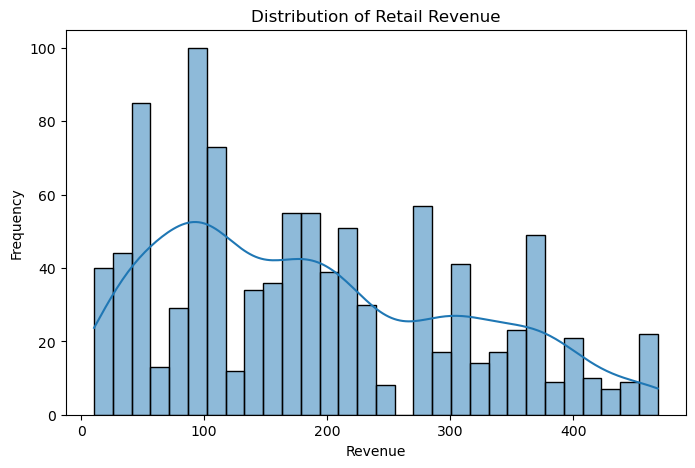

In [14]:
#distribution analysis
print(df3["LineRevenue"].describe())

# Revenue distribution
plt.figure(figsize=(8, 5))
sns.histplot(df3["LineRevenue"], bins=30, kde=True)

plt.title("Distribution of Retail Revenue")
plt.xlabel("Revenue")
plt.ylabel("Frequency")
plt.show()

In [16]:
#outliers
Q1 = df3["LineRevenue"].quantile(0.25)
Q3 = df3["LineRevenue"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df3["LineRevenue"] < lower) |
    (df3["LineRevenue"] > upper)
]

print("Number of outliers:", len(outliers))

Number of outliers: 0


C:\Users\RSC\AppData\Local\Temp\ipykernel_8152\311172043.py:10: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  outliers = df[


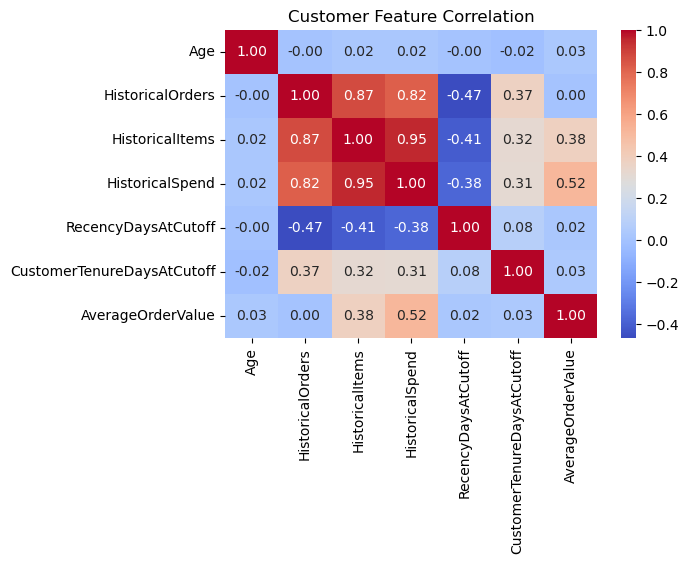

In [29]:
features = df

corr = features.select_dtypes(
    include="number"
).corr()

plt.figure(figsize=(6,4))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Feature Correlation")
plt.show()

In [20]:
#performance analysis
customer_performance = df3.groupby(
    "CustomerID"
).agg(
    TotalRevenue=("LineRevenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    TotalOrders=("InvoiceNo", "nunique")
).reset_index()

customer_performance = customer_performance.sort_values(
    by="TotalRevenue",
    ascending=False
)

print(customer_performance.head(10))

   CustomerID  TotalRevenue  TotalQuantity  TotalOrders
32     C00033       4889.91             62           10
46     C00047       4678.20             53            9
48     C00049       4615.52             53            9
9      C00010       4565.19             64           12
51     C00052       4435.97             59           11
64     C00065       4271.54             52           10
55     C00056       4229.79             51            9
15     C00016       4225.26             59           11
43     C00044       4184.27             53            8
56     C00057       4157.54             48            9
